##  Heart Disease Prediction Capstone Project

Educational classification project. Place values.csv and labels.csv beside this notebook and run cells from top to bottom. The supplied files are included beside it. Dataset contains 180 matched patients, so estimates may be unstable. This work is educational, not clinically validated, and not intended to guide diagnosis or treatment.

### Workflow
Merge by patient_id; 
inspect data quality; 
perform EDA; 
and compare exactly four models: Logistic Regression, Random Forest, K-Nearest Neighbors (KNN), and Support Vector Machine (SVM). 
Reserve a stratified test set. Fit all preprocessing inside pipelines and use five-fold stratified cross-validation on training data.

In [1]:
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
 roc_auc_score, classification_report, ConfusionMatrixDisplay, make_scorer, RocCurveDisplay)


ImportError: DLL load failed while importing ccalendar: An Application Control policy has blocked this file.

### 1. Load and merge data

In [ ]:
from pathlib import Path

values = pd.read_csv("C:\\Users\\asdee\\OneDrive\\Desktop\\Heart_Disease_Prediction_Capstone_Project\\values.csv")
labels = pd.read_csv("C:\\Users\\asdee\\OneDrive\\Desktop\\Heart_Disease_Prediction_Capstone_Project\\labels.csv")

print("Values",values.head())
print("Labels",labels.head())


Values   patient_id  slope_of_peak_exercise_st_segment               thal  \
0     0z64un                                  1             normal   
1     ryoo3j                                  2             normal   
2     yt1s1x                                  1             normal   
3     l2xjde                                  1  reversible_defect   
4     oyt4ek                                  3  reversible_defect   

   resting_blood_pressure  chest_pain_type  num_major_vessels  \
0                     128                2                  0   
1                     110                3                  0   
2                     125                4                  3   
3                     152                4                  0   
4                     178                1                  0   

   fasting_blood_sugar_gt_120_mg_per_dl  resting_ekg_results  \
0                                     0                    2   
1                                     0              

In [ ]:

KEY = "patient_id"
TARGET = "heart_disease_present"


data = values.merge(
    labels[[KEY, TARGET]],
    on=KEY,
    how="inner",
    validate="one_to_one",
    indicator=True
)
unmatched_values = int((~values[KEY].isin(labels[KEY])).sum())
unmatched_labels = int((~labels[KEY].isin(values[KEY])).sum())
data = data.drop(columns="_merge")

print("values.csv shape: {values.shape}")
print("labels.csv shape: {labels.shape}")
print("Merged dataset shape: {data.shape}")
print("Feature rows without labels: {unmatched_values}")
print("Label rows without features: {unmatched_labels}")
print("Matched patients: {len(data)}")
display(data.head())

values.csv shape: {values.shape}
labels.csv shape: {labels.shape}
Merged dataset shape: {data.shape}
Feature rows without labels: {unmatched_values}
Label rows without features: {unmatched_labels}
Matched patients: {len(data)}


,patient_id,slope_of_peak_exercise_st_segment,thal,resting_blood_pressure,chest_pain_type,num_major_vessels,fasting_blood_sugar_gt_120_mg_per_dl,resting_ekg_results,serum_cholesterol_mg_per_dl,oldpeak_eq_st_depression,sex,age,max_heart_rate_achieved,exercise_induced_angina,heart_disease_present
0,0z64un,1,normal,128,2,0,0,2,308,0.0,1,45,170,0,0
1,ryoo3j,2,normal,110,3,0,0,0,214,1.6,0,54,158,0,0
2,yt1s1x,1,normal,125,4,3,0,2,304,0.0,1,77,162,1,1
3,l2xjde,1,reversible_defect,152,4,0,0,0,223,0.0,1,40,181,0,1
4,oyt4ek,3,reversible_defect,178,1,0,0,2,270,4.2,1,59,145,0,0


### 2. Data understanding and quality checks
Investigate unexpected values against the source brief; do not silently change them.

In [ ]:
print("Dataset dimensions:", data.shape)

print("\nColumn names and data types:")
display(data.dtypes.rename("Data type").to_frame())

print("\nDataset information:")
data.info()

print("\nDescriptive statistics:")
display(data.describe(include="all").T)

print("\nMissing-value report:")
missing_report = pd.DataFrame({
    "Missing count": data.isna().sum(),
    "Missing percentage": (data.isna().mean() * 100).round(2)
}).sort_values("Missing count", ascending=False)
display(missing_report)

print("\nDuplicate checks:")
print("Exact duplicate rows:", int(data.duplicated().sum()))
print("Duplicate patient IDs:", int(data[KEY].duplicated().sum()))

print("\nTarget distribution:")
if data[TARGET].isna().any():
    raise ValueError("Target contains missing labels; do not impute the outcome.")
if not set(data[TARGET].dropna().unique()).issubset({0, 1}):
    raise ValueError("Expected binary target encoded as 0 and 1.")

target_counts = data[TARGET].value_counts(dropna=False).sort_index()
target_report = pd.DataFrame({
    "Count": target_counts,
    "Percentage": (target_counts / len(data) * 100).round(2)
})
display(target_report)

constant_cols = [
    col for col in data.columns
    if col not in [KEY, TARGET] and data[col].nunique(dropna=False) <= 1
]
print("\nConstant predictor columns:", constant_cols if constant_cols else "None detected")

print("\nObserved values for low-cardinality columns:")
for col in data.columns:
    if col not in [KEY, TARGET] and data[col].nunique(dropna=True) <= 12:
        print(f"\n{col}")
        display(data[col].value_counts(dropna=False).to_frame("Count"))

Dataset dimensions: (180, 15)

Column names and data types:


,Data type
patient_id,str
slope_of_peak_exercise_st_segment,int64
thal,str
resting_blood_pressure,int64
chest_pain_type,int64
num_major_vessels,int64
fasting_blood_sugar_gt_120_mg_per_dl,int64
resting_ekg_results,int64
serum_cholesterol_mg_per_dl,int64
oldpeak_eq_st_depression,float64



Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 180 entries, 0 to 179
Data columns (total 15 columns):
 #   Column                                Non-Null Count  Dtype  
---  ------                                --------------  -----  
 0   patient_id                            180 non-null    str    
 1   slope_of_peak_exercise_st_segment     180 non-null    int64  
 2   thal                                  180 non-null    str    
 3   resting_blood_pressure                180 non-null    int64  
 4   chest_pain_type                       180 non-null    int64  
 5   num_major_vessels                     180 non-null    int64  
 6   fasting_blood_sugar_gt_120_mg_per_dl  180 non-null    int64  
 7   resting_ekg_results                   180 non-null    int64  
 8   serum_cholesterol_mg_per_dl           180 non-null    int64  
 9   oldpeak_eq_st_depression              180 non-null    float64
 10  sex                                   180 non-null    int64  
 11  age     

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
patient_id,180,180,0z64un,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
slope_of_peak_exercise_st_segment,180.0,NaN,NaN,NaN,1.55,0.618838,1.0,1.0,1.0,2.0,3.0
thal,180,3,normal,98,NaN,NaN,NaN,NaN,NaN,NaN,NaN
resting_blood_pressure,180.0,NaN,NaN,NaN,131.311111,17.010443,94.0,120.0,130.0,140.0,180.0
chest_pain_type,180.0,NaN,NaN,NaN,3.155556,0.938454,1.0,3.0,3.0,4.0,4.0
num_major_vessels,180.0,NaN,NaN,NaN,0.694444,0.969347,0.0,0.0,0.0,1.0,3.0
fasting_blood_sugar_gt_120_mg_per_dl,180.0,NaN,NaN,NaN,0.161111,0.368659,0.0,0.0,0.0,0.0,1.0
resting_ekg_results,180.0,NaN,NaN,NaN,1.05,0.998742,0.0,0.0,2.0,2.0,2.0
serum_cholesterol_mg_per_dl,180.0,NaN,NaN,NaN,249.211111,52.717969,126.0,213.75,245.5,281.25,564.0
oldpeak_eq_st_depression,180.0,NaN,NaN,NaN,1.01,1.121357,0.0,0.0,0.8,1.6,6.2



Missing-value report:


,Missing count,Missing percentage
patient_id,0,0.0
slope_of_peak_exercise_st_segment,0,0.0
thal,0,0.0
resting_blood_pressure,0,0.0
chest_pain_type,0,0.0
num_major_vessels,0,0.0
fasting_blood_sugar_gt_120_mg_per_dl,0,0.0
resting_ekg_results,0,0.0
serum_cholesterol_mg_per_dl,0,0.0
oldpeak_eq_st_depression,0,0.0


... (14 outputs left out)


sex


,Count
sex,
1,124
0,56



exercise_induced_angina


,Count
exercise_induced_angina,
0,123
1,57


### 3. Exploratory data analysis
Plots describe this dataset only; small subgroup patterns are noisy and do not establish causation.

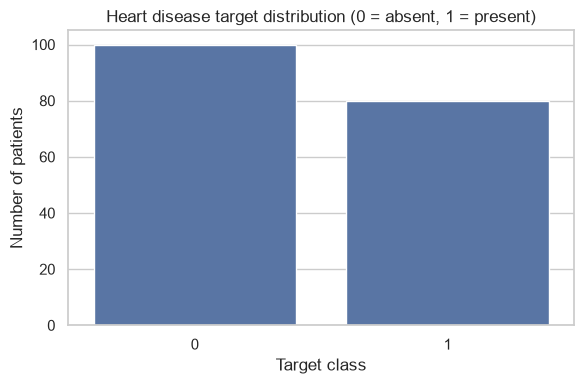

Numerical features: ['slope_of_peak_exercise_st_segment', 'resting_blood_pressure', 'chest_pain_type', 'num_major_vessels', 'fasting_blood_sugar_gt_120_mg_per_dl', 'resting_ekg_results', 'serum_cholesterol_mg_per_dl', 'oldpeak_eq_st_depression', 'sex', 'age', 'max_heart_rate_achieved', 'exercise_induced_angina']
Categorical features: ['thal']


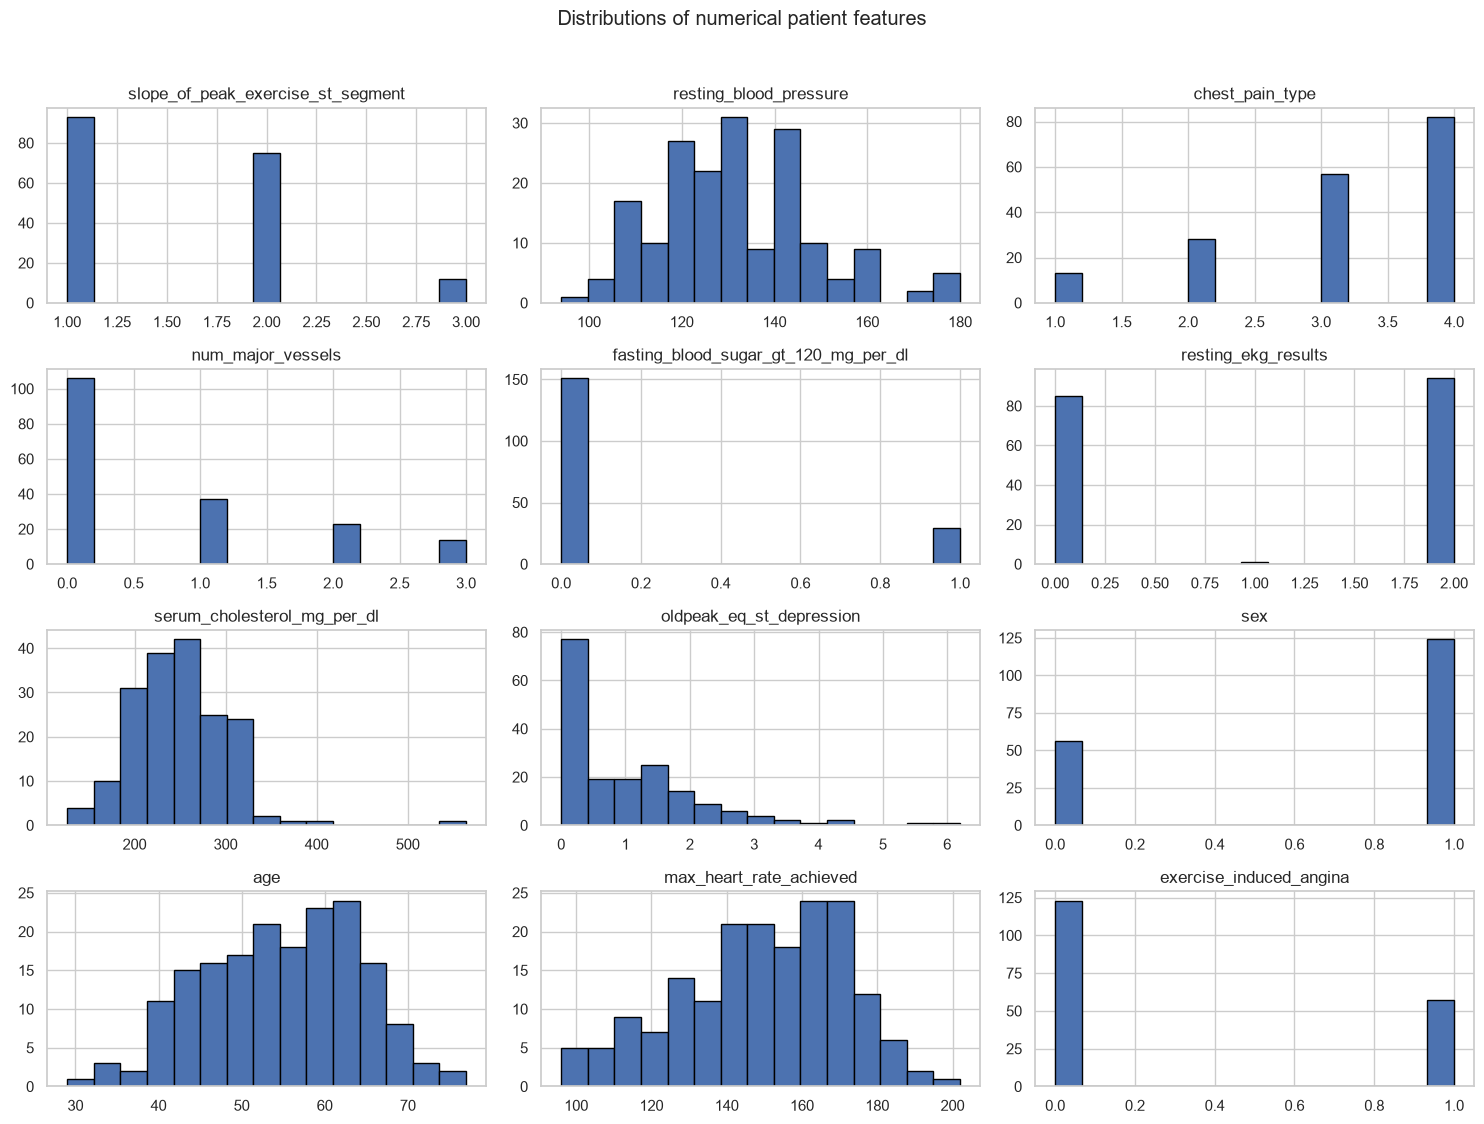

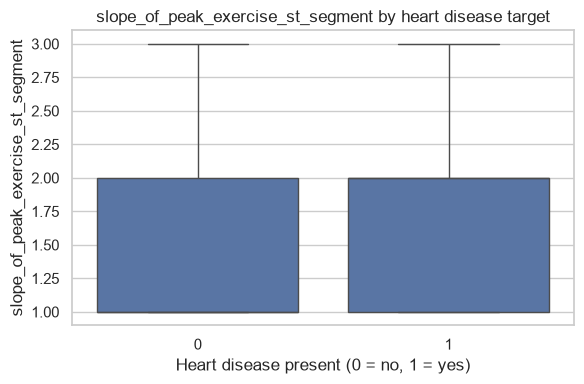

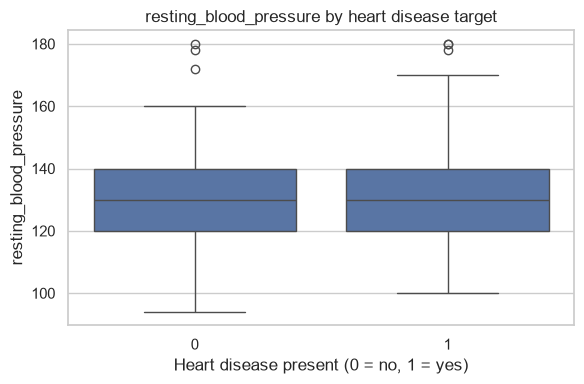

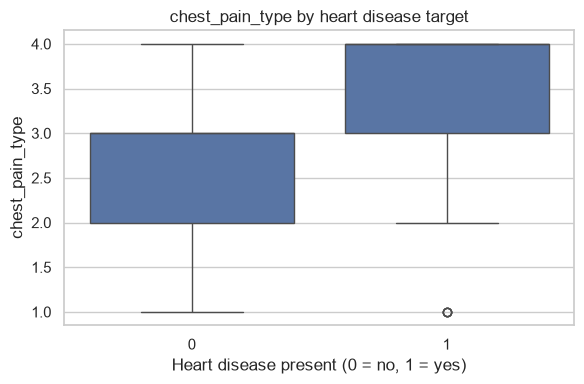

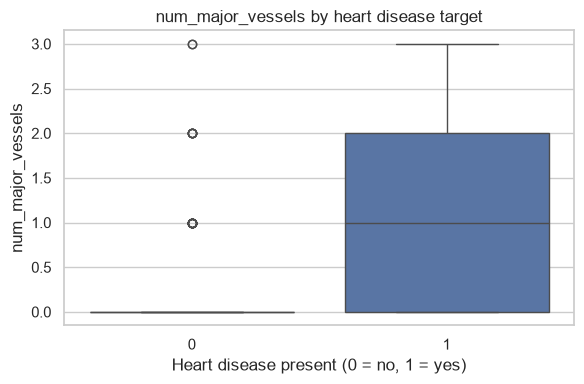

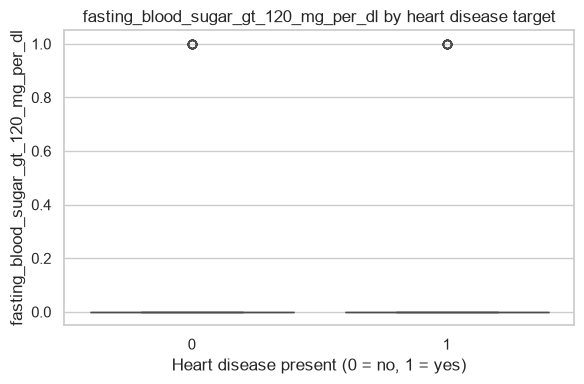

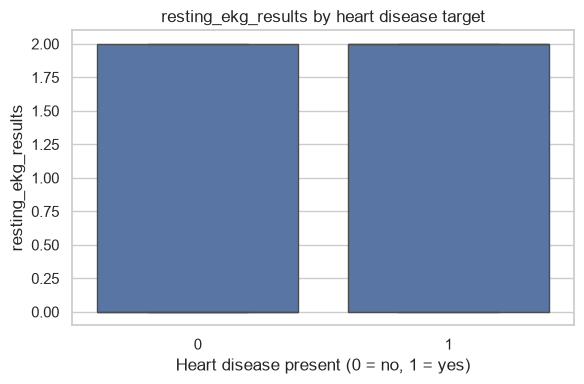

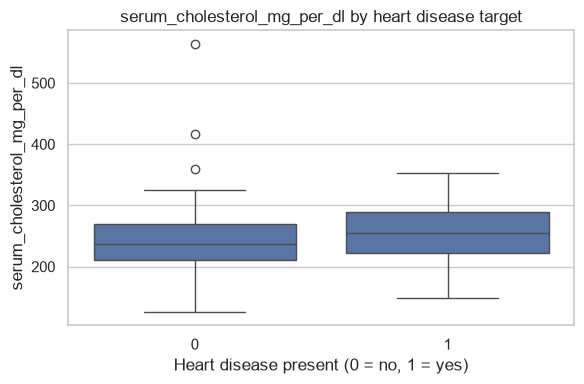

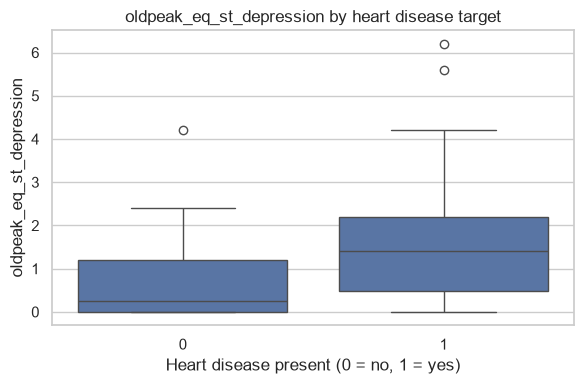

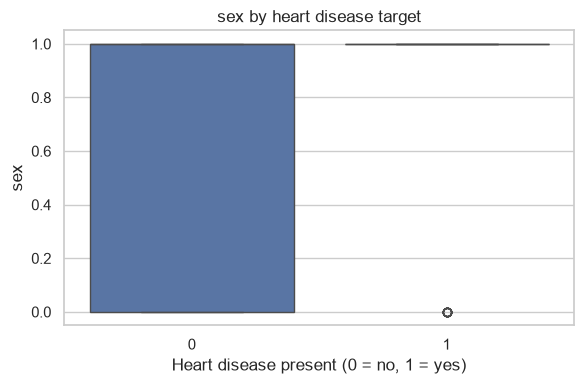

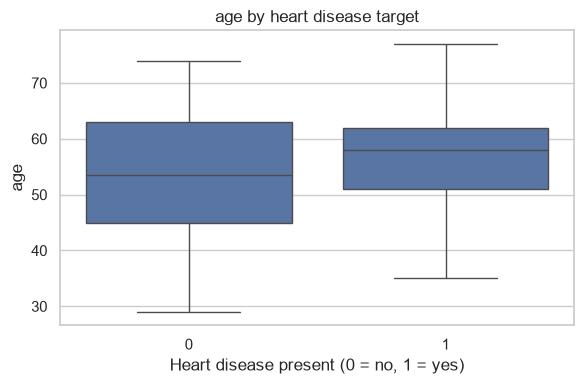

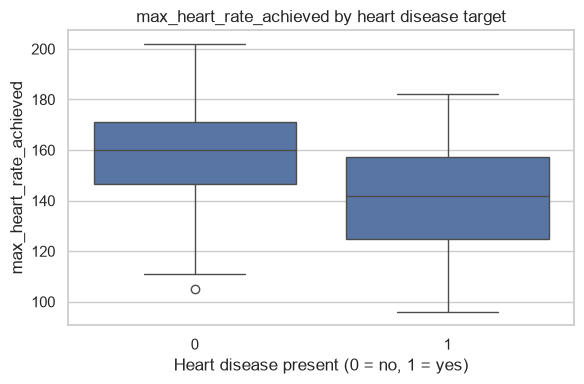

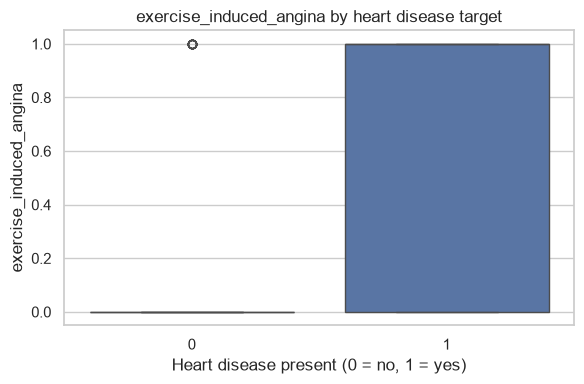


Distribution of thal:


,Count
thal,
normal,98
reversible_defect,74
fixed_defect,8


Heart disease proportion by thal:


heart_disease_present,0,1
thal,,
fixed_defect,0.500,0.500
normal,0.796,0.204
reversible_defect,0.243,0.757


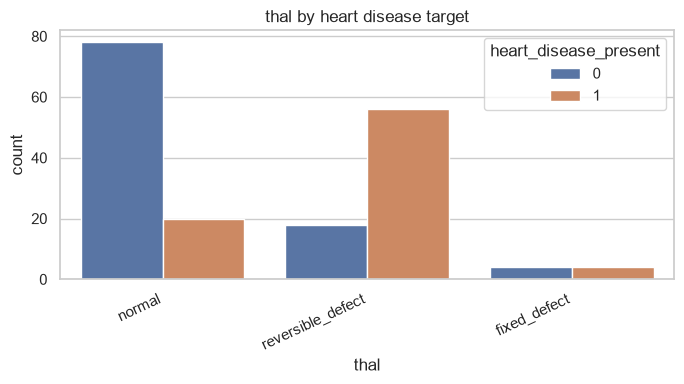


Heart disease rate by sex:


,Patients,Heart_disease_rate
sex,,
0,56,19.6
1,124,55.6



Heart disease rate by chest_pain_type:


,Patients,Heart_disease_rate
chest_pain_type,,
1,13,30.8
2,28,14.3
3,57,22.8
4,82,72.0


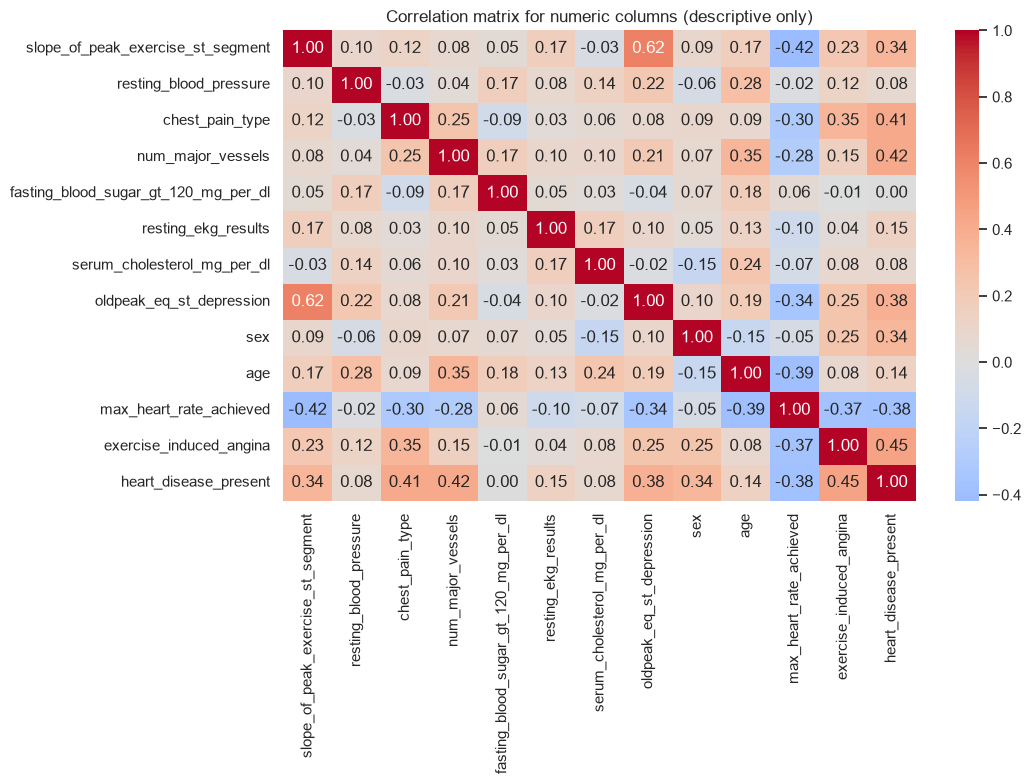


EDA INTERPRETATION
------------------
Target distribution: class 0 = 100 (55.6%); class 1 = 80 (44.4%). This describes the class balance and should be considered when interpreting accuracy.
slope_of_peak_exercise_st_segment: median is 1.00 for class 0 and 2.00 for class 1; means are 1.36 and 1.79, respectively. Compare the distributions and overlap in the corresponding plots; these are associations, not evidence of causation.
resting_blood_pressure: median is 130.00 for class 0 and 130.00 for class 1; means are 130.12 and 132.80, respectively. Compare the distributions and overlap in the corresponding plots; these are associations, not evidence of causation.
chest_pain_type: median is 3.00 for class 0 and 4.00 for class 1; means are 2.81 and 3.59, respectively. Compare the distributions and overlap in the corresponding plots; these are associations, not evidence of causation.
num_major_vessels: median is 0.00 for class 0 and 1.00 for class 1; means are 0.33 and 1.15, respectively. Com

In [ ]:
sns.set_theme(style="whitegrid")

# Target balance
plt.figure(figsize=(6, 4))
sns.countplot(data=data, x=TARGET)
plt.title("Heart disease target distribution (0 = absent, 1 = present)")
plt.xlabel("Target class")
plt.ylabel("Number of patients")
plt.tight_layout()
plt.show()

numeric_features = data.select_dtypes(include=np.number).columns.drop(
    [KEY, TARGET], errors="ignore"
).tolist()
categorical_features = [
    c for c in data.columns
    if c not in [KEY, TARGET] and c not in numeric_features
]

print("Numerical features:", numeric_features)
print("Categorical features:", categorical_features)

# Numerical feature distributions
if numeric_features:
    data[numeric_features].hist(figsize=(15, 11), bins=15, edgecolor="black")
    plt.suptitle("Distributions of numerical patient features", y=1.02)
    plt.tight_layout()
    plt.show()

# Numerical features compared across target classes
for col in numeric_features:
    plt.figure(figsize=(6, 4))
    sns.boxplot(data=data, x=TARGET, y=col)
    plt.title(f"{col} by heart disease target")
    plt.xlabel("Heart disease present (0 = no, 1 = yes)")
    plt.tight_layout()
    plt.show()

# Categorical feature counts and target proportions
for col in categorical_features:
    print(f"\nDistribution of {col}:")
    display(data[col].value_counts(dropna=False).to_frame("Count"))
    print(f"Heart disease proportion by {col}:")
    ctab = pd.crosstab(data[col], data[TARGET], normalize="index").round(3)
    display(ctab)
    plt.figure(figsize=(7, 4))
    sns.countplot(data=data, x=col, hue=TARGET)
    plt.title(f"{col} by heart disease target")
    plt.xticks(rotation=25, ha="right")
    plt.tight_layout()
    plt.show()

# Age/sex and chest-pain subgroup summaries where those fields exist.
for col in ["sex", "chest_pain_type"]:
    if col in data.columns:
        print(f"\nHeart disease rate by {col}:")
        display(data.groupby(col, dropna=False)[TARGET].agg(
            Patients="count", Heart_disease_rate="mean"
        ).assign(Heart_disease_rate=lambda x: (100*x["Heart_disease_rate"]).round(1)))

# Correlation is descriptive, not causal; encoded category codes may be ordinal.
if len(numeric_features) > 1:
    corr = data[numeric_features + [TARGET]].corr(numeric_only=True)
    plt.figure(figsize=(11, 8))
    sns.heatmap(corr, cmap="coolwarm", center=0, annot=True, fmt=".2f")
    plt.title("Correlation matrix for numeric columns (descriptive only)")
    plt.tight_layout()
    plt.show()

# ------------------------------------------------------------
# Written EDA interpretation (computed from this dataset)
# ------------------------------------------------------------
print("\nEDA INTERPRETATION")
print("------------------")

class_counts = data[TARGET].value_counts().sort_index()
class_pct = (class_counts / len(data) * 100).round(1)
print(
    f"Target distribution: class 0 = {class_counts.get(0, 0)} "
    f"({class_pct.get(0, 0)}%); class 1 = {class_counts.get(1, 0)} "
    f"({class_pct.get(1, 0)}%). "
    "This describes the class balance and should be considered when interpreting accuracy."
)

for col in numeric_features:
    grouped = data.groupby(TARGET)[col].agg(["count", "median", "mean"])
    if 0 in grouped.index and 1 in grouped.index:
        median0 = grouped.loc[0, "median"]
        median1 = grouped.loc[1, "median"]
        mean0 = grouped.loc[0, "mean"]
        mean1 = grouped.loc[1, "mean"]
        print(
            f"{col}: median is {median0:.2f} for class 0 and {median1:.2f} "
            f"for class 1; means are {mean0:.2f} and {mean1:.2f}, respectively. "
            "Compare the distributions and overlap in the corresponding plots; "
            "these are associations, not evidence of causation."
        )

for col in categorical_features:
    rates = data.groupby(col, dropna=False)[TARGET].mean().sort_values(ascending=False)
    if len(rates):
        highest_category = rates.index[0]
        lowest_category = rates.index[-1]
        print(
            f"{col}: observed heart-disease proportions range from "
            f"{rates.iloc[-1]:.1%} in category {lowest_category!r} to "
            f"{rates.iloc[0]:.1%} in category {highest_category!r}. "
            "Check category sample sizes before interpreting differences."
        )

if len(numeric_features) > 0:
    correlations = data[numeric_features + [TARGET]].corr(numeric_only=True)[TARGET]
    correlations = correlations.drop(labels=[TARGET], errors="ignore").dropna()
    if len(correlations):
        strongest = correlations.abs().sort_values(ascending=False).head(3)
        print(
            "Largest absolute numeric correlations with the target: "
            + ", ".join(
                f"{name} ({correlations[name]:.3f})" for name in strongest.index
            )
            + ". Correlation does not imply causation, and integer-coded categories "
              "may not have meaningful linear correlations."
        )

print(
    "\nInterpretation note: Use the printed statistics together with the plots. "
    "Small sample sizes, overlapping distributions, confounding, and category "
    "encoding can limit conclusions. Do not infer clinical causality from EDA."
)

### 4. Split and preprocess without leakage
Exclude patient_id as an identifier. Split before fitting transformations. Numeric variables are median-imputed and standardized; categorical variables are mode-imputed and one-hot encoded. Pipeline fitting occurs within each training fold.

In [ ]:
X=data.drop(columns=[KEY,TARGET]); y=data[TARGET].astype(int)
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=.20,random_state=42,stratify=y)
num=X_train.select_dtypes(include=np.number).columns.tolist()
cat=X_train.select_dtypes(exclude=np.number).columns.tolist()
prep=ColumnTransformer([
 ("numeric",Pipeline([("imputer",SimpleImputer(strategy="median")),("scale",StandardScaler())]),num),
 ("categorical",Pipeline([("imputer",SimpleImputer(strategy="most_frequent")),("onehot",OneHotEncoder(handle_unknown="ignore"))]),cat)
])
print("Train/test rows:",len(X_train),len(X_test))
y_train.value_counts(normalize=True).to_frame("training proportion")

Train/test rows: 144 36


,training proportion
heart_disease_present,
0,0.555556
1,0.444444


### 5. Four models and stratified cross-validation
Cross-validation uses training data only. Macro averages weight both classes equally.

In [ ]:
models={
 "Logistic Regression":LogisticRegression(max_iter=2000,class_weight="balanced",random_state=42),
 "Random Forest":RandomForestClassifier(n_estimators=300,class_weight="balanced",random_state=42),
 "K-Nearest Neighbors":KNeighborsClassifier(n_neighbors=5),
 "Support Vector Machine":SVC(kernel="rbf",probability=True,class_weight="balanced",random_state=42)
}
cv=StratifiedKFold(n_splits=5,shuffle=True,random_state=42)
scoring={"accuracy":"accuracy",
 "precision_macro":make_scorer(precision_score,average="macro",zero_division=0),
 "recall_macro":make_scorer(recall_score,average="macro",zero_division=0),
 "f1_macro":make_scorer(f1_score,average="macro",zero_division=0),"roc_auc":"roc_auc"}
pipes={}; rows=[]
for name,model in models.items():
    pipe=Pipeline([("preprocess",prep),("model",model)]); pipes[name]=pipe
    scores=cross_validate(pipe,X_train,y_train,cv=cv,scoring=scoring,n_jobs=-1)
    row={"Model":name}
    for metric in scoring:
        vals=scores["test_"+metric]; row["CV "+metric+" mean"]=vals.mean(); row["CV "+metric+" std"]=vals.std(ddof=1)
    rows.append(row)
cv_results=pd.DataFrame(rows).set_index("Model")
display(cv_results.round(3))

,CV accuracy mean,CV accuracy std,CV precision_macro mean,CV precision_macro std,CV recall_macro mean,CV recall_macro std,CV f1_macro mean,CV f1_macro std,CV roc_auc mean,CV roc_auc std
Model,,,,,,,,,,
Logistic Regression,0.792,0.049,0.808,0.067,0.789,0.046,0.787,0.047,0.866,0.096
Random Forest,0.806,0.075,0.815,0.076,0.804,0.073,0.802,0.077,0.871,0.058
K-Nearest Neighbors,0.771,0.056,0.787,0.058,0.765,0.061,0.762,0.060,0.848,0.068
Support Vector Machine,0.820,0.056,0.833,0.063,0.819,0.052,0.816,0.056,0.874,0.093


### 6. Held-out evaluation
Each model is fitted on all training rows and evaluated once on the untouched test set. Scores are uncertain estimates from a small sample.

In [ ]:
from sklearn.base import clone

results = []
trained = {}
classwise_reports = {}

for name, pipe in pipes.items():
    pipe.fit(X_train, y_train)
    trained[name] = pipe
    pred = pipe.predict(X_test)
    prob = pipe.predict_proba(X_test)[:, 1]

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision (macro)": precision_score(y_test, pred, average="macro", zero_division=0),
        "Recall (macro)": recall_score(y_test, pred, average="macro", zero_division=0),
        "F1 (macro)": f1_score(y_test, pred, average="macro", zero_division=0),
        "Positive-class precision": precision_score(y_test, pred, pos_label=1, zero_division=0),
        "Positive-class recall": recall_score(y_test, pred, pos_label=1, zero_division=0),
        "Positive-class F1": f1_score(y_test, pred, pos_label=1, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, prob)
    })
    classwise_reports[name] = classification_report(
        y_test, pred, output_dict=True, zero_division=0
    )

test_results = pd.DataFrame(results).set_index("Model")
print("Held-out test metrics (single stratified split):")
display(test_results.round(3))

Held-out test metrics (single stratified split):


c:\Users\asdee\AppData\Local\Python\pythoncore-3.15-64\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


,Accuracy,Precision (macro),Recall (macro),F1 (macro),Positive-class precision,Positive-class recall,Positive-class F1,ROC-AUC
Model,,,,,,,,
Logistic Regression,0.833,0.833,0.838,0.833,0.778,0.875,0.824,0.941
Random Forest,0.861,0.881,0.875,0.861,0.762,1.000,0.865,0.942
K-Nearest Neighbors,0.889,0.888,0.888,0.888,0.875,0.875,0.875,0.914
Support Vector Machine,0.806,0.810,0.812,0.805,0.737,0.875,0.800,0.947


### Confusion matrices and reports
Rows are actual classes and columns predicted classes. Review false negatives and false positives; error trade-offs need domain review.

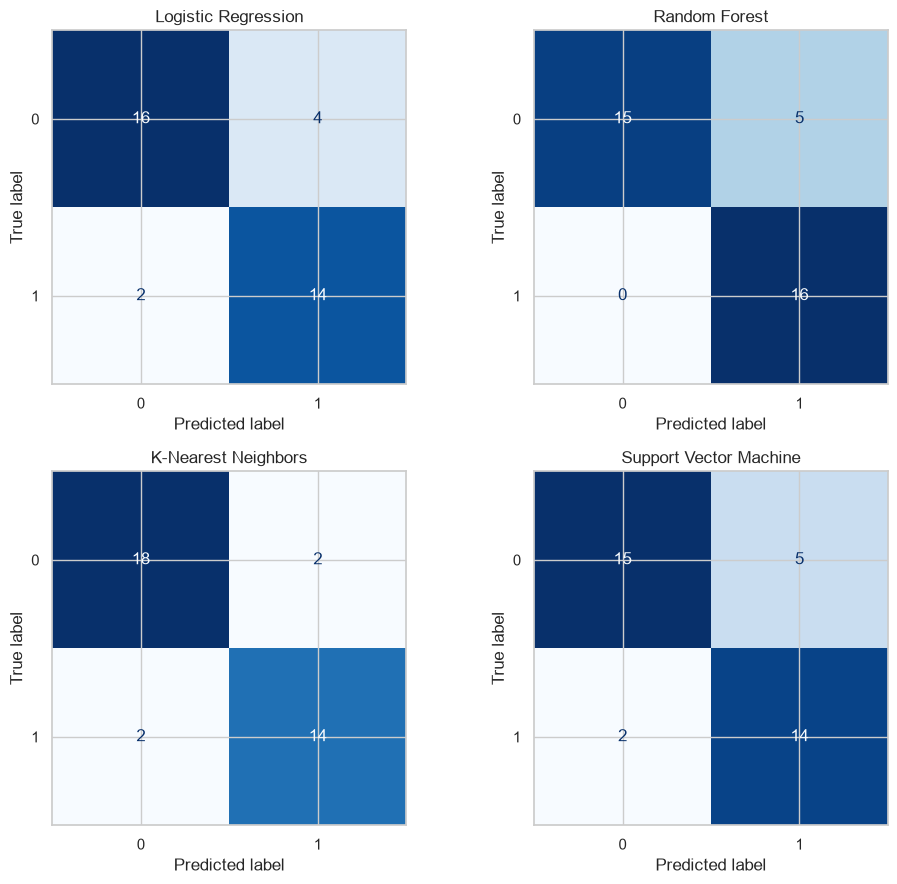


 Logistic Regression
              precision    recall  f1-score   support

           0       0.89      0.80      0.84        20
           1       0.78      0.88      0.82        16

    accuracy                           0.83        36
   macro avg       0.83      0.84      0.83        36
weighted avg       0.84      0.83      0.83        36


 Random Forest
              precision    recall  f1-score   support

           0       1.00      0.75      0.86        20
           1       0.76      1.00      0.86        16

    accuracy                           0.86        36
   macro avg       0.88      0.88      0.86        36
weighted avg       0.89      0.86      0.86        36


 K-Nearest Neighbors
              precision    recall  f1-score   support

           0       0.90      0.90      0.90        20
           1       0.88      0.88      0.88        16

    accuracy                           0.89        36
   macro avg       0.89      0.89      0.89        36
weighted avg  

In [ ]:
fig,axes=plt.subplots(2,2,figsize=(10,9))
for ax,(name,pipe) in zip(axes.flat,trained.items()):
    ConfusionMatrixDisplay.from_estimator(pipe,X_test,y_test,ax=ax,cmap="Blues",colorbar=False); ax.set_title(name)
plt.tight_layout(); plt.show()
for name,pipe in trained.items():
    print("\n",name); print(classification_report(y_test,pipe.predict(X_test),zero_division=0))

### 7. Model comparison
Compare cross-validation and test scores together. Small prediction changes can materially alter results. Observed score differences do not prove superiority.

Cross-validation and held-out test comparison:


,CV accuracy mean,CV accuracy std,CV precision_macro mean,CV precision_macro std,CV recall_macro mean,CV recall_macro std,CV f1_macro mean,CV f1_macro std,CV roc_auc mean,CV roc_auc std,Test Accuracy,Test Precision (macro),Test Recall (macro),Test F1 (macro),Test Positive-class precision,Test Positive-class recall,Test Positive-class F1,Test ROC-AUC
Model,,,,,,,,,,,,,,,,,,
Logistic Regression,0.792,0.049,0.808,0.067,0.789,0.046,0.787,0.047,0.866,0.096,0.833,0.833,0.838,0.833,0.778,0.875,0.824,0.941
Random Forest,0.806,0.075,0.815,0.076,0.804,0.073,0.802,0.077,0.871,0.058,0.861,0.881,0.875,0.861,0.762,1.000,0.865,0.942
K-Nearest Neighbors,0.771,0.056,0.787,0.058,0.765,0.061,0.762,0.060,0.848,0.068,0.889,0.888,0.888,0.888,0.875,0.875,0.875,0.914
Support Vector Machine,0.820,0.056,0.833,0.063,0.819,0.052,0.816,0.056,0.874,0.093,0.806,0.810,0.812,0.805,0.737,0.875,0.800,0.947


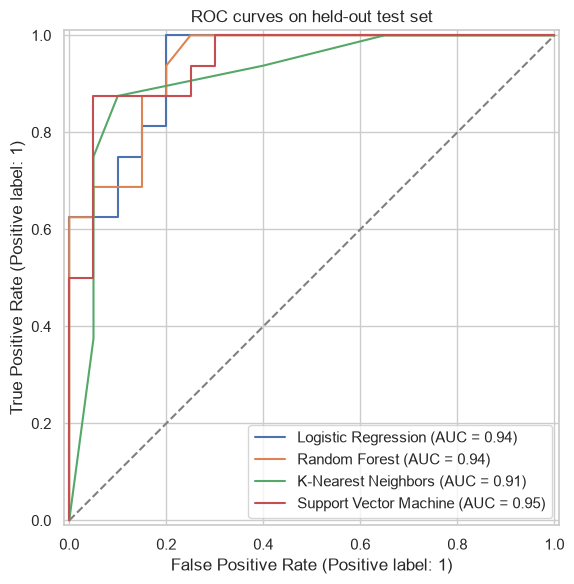

Provisional model ranked first by mean CV macro recall, with CV ROC-AUC as tie-breaker:
Support Vector Machine

Cross-validation ranking:


,CV recall_macro mean,CV recall_macro std,CV roc_auc mean,CV roc_auc std
Model,,,,
Support Vector Machine,0.819,0.052,0.874,0.093
Random Forest,0.804,0.073,0.871,0.058
Logistic Regression,0.789,0.046,0.866,0.096
K-Nearest Neighbors,0.765,0.061,0.848,0.068



Held-out positive-class recall for context:


,Positive-class recall,Positive-class precision,Positive-class F1,ROC-AUC
Model,,,,
Random Forest,1.000,0.762,0.865,0.942
Logistic Regression,0.875,0.778,0.824,0.941
K-Nearest Neighbors,0.875,0.875,0.875,0.914
Support Vector Machine,0.875,0.737,0.800,0.947



Interpretation: This is a provisional educational ranking, not a production approval. Cross-validation estimates are based on a small dataset and should be confirmed on larger, representative, external data. Consider clinical costs of false negatives and false positives before setting a threshold.


In [ ]:
comparison = cv_results.join(test_results.add_prefix("Test "))
print("Cross-validation and held-out test comparison:")
display(comparison.round(3))

fig, ax = plt.subplots(figsize=(8, 6))
for name, pipe in trained.items():
    RocCurveDisplay.from_estimator(pipe, X_test, y_test, name=name, ax=ax)
ax.plot([0, 1], [0, 1], "--", color="gray", label="Chance")
ax.set_title("ROC curves on held-out test set")
plt.tight_layout()
plt.show()

# Primary ranking: mean CV macro recall (balanced sensitivity across both classes).
# Secondary context: mean CV ROC-AUC and held-out positive-class recall.
ranking = cv_results.sort_values(
    by=["CV recall_macro mean", "CV roc_auc mean"],
    ascending=False
)
recommended_model = ranking.index[0]
print("Provisional model ranked first by mean CV macro recall, with CV ROC-AUC as tie-breaker:")
print(recommended_model)
print("\nCross-validation ranking:")
display(ranking[["CV recall_macro mean", "CV recall_macro std",
                 "CV roc_auc mean", "CV roc_auc std"]].round(3))

print("\nHeld-out positive-class recall for context:")
display(test_results[["Positive-class recall", "Positive-class precision",
                      "Positive-class F1", "ROC-AUC"]].sort_values(
                          "Positive-class recall", ascending=False
                      ).round(3))

print(
    "\nInterpretation: This is a provisional educational ranking, not a production "
    "approval. Cross-validation estimates are based on a small dataset and should be "
    "confirmed on larger, representative, external data. Consider clinical costs of "
    "false negatives and false positives before setting a threshold."
)

### 8. Hospital recommendations

The following are recommendations for further assessment and planning, not instructions to diagnose or treat patients from this model.

1. **Support earlier risk assessment:** Use routinely collected clinical information to help identify patients who may benefit from a clinician-led cardiovascular risk review.
2. **Monitor key measurements:** Encourage appropriate follow-up of blood pressure, cholesterol, blood glucose, symptoms, and other risk factors according to clinical guidelines.
3. **Prioritise clinical review, not automated decisions:** If a future validated decision-support tool flags a patient, a qualified healthcare professional should review the full clinical context and decide whether additional examination is appropriate.
4. **Review missed cases:** During validation, examine false negatives carefully with clinicians because missed disease may carry substantial consequences.
5. **Check fairness and generalisability:** Evaluate performance across relevant age and sex groups and across hospitals or populations before considering deployment.
6. **Validate before use:** Conduct external and prospective validation, calibration assessment, workflow testing, privacy/security review, and applicable regulatory/governance review.
7. **Maintain human oversight:** Do not use this educational model to diagnose, triage, prescribe, or change treatment.

The supplied dataset is small (180 matched patients according to the project review) and does not establish clinical effectiveness or safety.

### 9. Challenges faced, techniques used, and reasons

| Challenge / consideration | Technique or response | Reason |
|---|---|---|
| Separate feature and label files | Merge on `patient_id` with one-to-one validation | Ensures each patient is matched to one label and prevents accidental many-to-many duplication. |
| Identifier is not a clinical predictor | Exclude `patient_id` from `X` | A random identifier has no intended clinical meaning and may create spurious patterns. |
| Missing values may occur | Median imputation for numeric variables and most-frequent imputation for categorical variables | Provides a consistent training workflow without dropping all records containing a missing feature. Confirm missingness from the displayed report. |
| Categorical predictors need numeric representation | One-hot encoding with unknown-category handling | Makes categories usable by the selected algorithms without imposing false numeric ordering. |
| Numeric predictors have different scales | Standardisation inside the preprocessing pipeline | Helps scale-sensitive algorithms such as Logistic Regression, KNN, and SVM. |
| Preprocessing can leak test/fold information | Use a `Pipeline` and `ColumnTransformer` within cross-validation | Ensures transformations are fitted only on the relevant training fold. |
| Small dataset and uncertain estimates | Stratified train/test split and five-fold stratified cross-validation | Preserves class proportions and provides more than one estimate, though uncertainty remains high. |
| False negatives and false positives have different implications | Report class-specific precision/recall and confusion matrices | Makes error types visible for clinical discussion rather than relying on accuracy alone. |
| Dataset representativeness and clinical validity are unknown | State limitations and require external/prospective validation | Performance on this sample cannot establish suitability for other patients or real clinical use. |

**Reporting rule:** Treat merge counts, missing-value counts, duplicate counts, constant columns, and class proportions printed above as observed findings. Treat scaling, encoding, leakage prevention, and external validation as methodological considerations. Do not claim a missing-data, duplicate, or class-imbalance problem unless the corresponding output confirms it.

### 10. Conclusion

This project follows the supplied brief by combining patient features and labels, examining the resulting dataset, preparing numerical and categorical predictors, and comparing four classification algorithms: Logistic Regression, Random Forest, K-Nearest Neighbors, and Support Vector Machine.

The model comparison uses stratified cross-validation on the training partition and a separate held-out test partition. Accuracy, macro precision, macro recall, macro F1-score, positive-class metrics, ROC-AUC, confusion matrices, and ROC curves provide complementary views of model behaviour. The provisional ranking is based primarily on mean cross-validation macro recall, with cross-validation ROC-AUC used as supporting context; the held-out results are reported separately.

The dataset contains only 180 matched patients according to the project description, so performance estimates are uncertain and may change with a different sample. No model from this exercise should be treated as clinically validated or production-ready. Larger representative datasets, external and prospective validation, calibration, subgroup evaluation, clinical review, and governance approval would be necessary before any real-world clinical decision-support use.

### Reproducibility
Random seeds are fixed. Keep both CSV files unchanged beside this notebook. Record package versions and data provenance when sharing.

In [ ]:
import sklearn
print('pandas:',pd.__version__)
print('scikit-learn:',sklearn.__version__)
print('NumPy:',np.__version__)

pandas: 3.1.0
scikit-learn: 1.9.1
NumPy: 2.5.4
